--- Exercício 1: ---
Q1 (Percentil 25): 13.0
Q2 (Mediana / Percentil 50): 14.0
Q3 (Percentil 75): 15.0

--- Exercício 2: ---
IQR (Q3 - Q1): 2.0
1.5 x IQR: 3.0
Limite Inferior: 10.0
Limite Superior: 18.0

Conclusão: O valor 150 ultrapassa os limites e É um candidato a outlier.
--- Exercício 3: ---
Q1:  150
Q2:  225.0
Q3:  300
IQR:  150
--- Exercício 4: ---
Q1: 112.5
Q3: 118.75
IQR: 6.25
Limite Inferior: 103.125
Limite Superior: 128.125
Candidatos a outlier: [220, 12]
Q1: 14
Q3: 18
IQR: 4
limite inferior: 8.0
limite superior: 24.0
lista de candidatos a outlier: [-30, 100]
--- Exercício 6: ---
Dados originais: [45, 50, 55, 60, 48, 52, 51, 98, 49, 53]
Q1: 49
Q3: 55
IQR: 6
Limite inferior: 40.0
Limite superior: 64.0
Candidatos a outlier: [98]

O valor 98 ultrapassou o limite superior 64.0.
Portanto, 98 é candidato a outlier pela Regra do IQR.
--- Exercício 7: ---
DataFrame original:
   ID_Maquina  Uso_Memoria_MB
0           1            2048
1           2            2100
2           3      

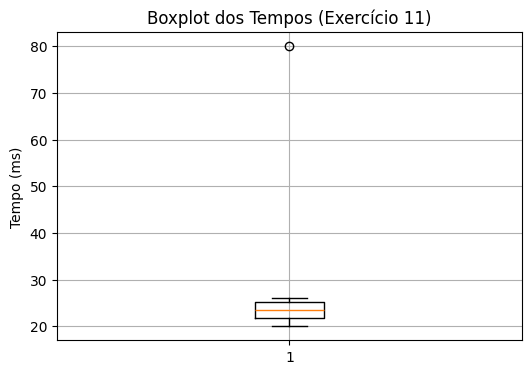

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dados fornecidos
dados = [12, 15, 14, 13, 16, 12, 14, 150, 13, 15]

# --- EXERCÍCIO 1: Calculando os quartis com NumPy ---
q1 = np.percentile(dados, 25)
q2 = np.percentile(dados, 50)
q3 = np.percentile(dados, 75)

print("--- Exercício 1: ---")
print(f"Q1 (Percentil 25): {q1}")
print(f"Q2 (Mediana / Percentil 50): {q2}")
print(f"Q3 (Percentil 75): {q3}")
print()

# --- EXERCÍCIO 2: Calculando o IQR e os Limites ---
iqr = q3 - q1
iqr_1_5 = 1.5 * iqr
limite_inferior = q1 - iqr_1_5
limite_superior = q3 + iqr_1_5

print("--- Exercício 2: ---")
print(f"IQR (Q3 - Q1): {iqr}")
print(f"1.5 x IQR: {iqr_1_5}")
print(f"Limite Inferior: {limite_inferior}")
print(f"Limite Superior: {limite_superior}")
print()

# Verificação do outlier
valor_analisado = 150
if valor_analisado > limite_superior or valor_analisado < limite_inferior:
    print(f"Conclusão: O valor {valor_analisado} ultrapassa os limites e É um candidato a outlier.")
else:
    print(f"Conclusão: O valor {valor_analisado} NÃO ultrapassa os limites e não é um outlier.")


# --- EXERCÍCIO 3: Encontrando Q1 e Q3 sem funções prontas de quartil ---
dados = [100, 150, 200, 250, 300, 350] # 225

def mediana(lista):
    if len(lista) % 2 == 0:
        Q2 = ( lista[len(lista) // 2] + lista[len(lista) // 2 - 1] )  / 2
    else:
        Q2 = lista[len(lista) // 2]
    return Q2

Q1 = mediana(dados[: len(dados) // 2])
Q2 = mediana(dados)
if len(dados) % 2 == 0:
    Q3 = mediana(dados[len(dados) // 2 :])
else:
    Q3 = mediana(dados[len(dados) // 2 + 1 :])

IQR = Q3 - Q1

print("--- Exercício 3: ---")
print("Q1: ", Q1)
print("Q2: ", Q2)
print("Q3: ", Q3)
print("IQR: ", IQR)


# --- EXERCÍCIO 4: Identificando outliers em uma lista ---
tensoes = [110, 115, 120, 118, 112, 220, 116, 114, 119, 12]

# Cálculo dos Quartis (Q1 e Q3)
q1 = np.percentile(tensoes, 25)
q3 = np.percentile(tensoes, 75)

# Cálculo do IQR
iqr = q3 - q1

#  Cálculo dos Limites Inferior e Superior
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Percorrer o vetor e armazenar os candidatos a outlier
outliers = []
for valor in tensoes:
    if valor < limite_inferior or valor > limite_superior:
        outliers.append(valor)

print("--- Exercício 4: ---")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")
print(f"Limite Inferior: {limite_inferior}")
print(f"Limite Superior: {limite_superior}")
print(f"Candidatos a outlier: {outliers}")


# --- EXERCÍCIO 5: Criando uma função para detectar outliers ---
def detectar_anomalias(dados, multiplicador=1.5):
    # Ordenando os dados para garantir o cálculo correto dos quartis
    dados_ord = sorted(dados)
    n = len(dados_ord)

    # 1 e 2. Calcular Q1 e Q3 utilizando a nossa função manual
    Q1 = mediana(dados_ord[: n // 2])
    if n % 2 == 0:
        Q3 = mediana(dados_ord[n // 2 :])
    else:
        Q3 = mediana(dados_ord[n // 2 + 1 :])

    # 3. Calcular IQR
    IQR = Q3 - Q1

    # 4 e 5. Calcular limites
    limite_inferior = Q1 - (multiplicador * IQR)
    limite_superior = Q3 + (multiplicador * IQR)

    # 6. Identificar candidatos a outlier
    outliers = [x for x in dados if x < limite_inferior or x > limite_superior]

    # 7. Retornar os valores
    return {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'limite inferior': limite_inferior,
        'limite superior': limite_superior,
        'lista de candidatos a outlier': outliers
    }

# Testando a função com alguns dados de exemplo
dados_teste = [10, 15, 14, 16, 20, 18, 15, 14, -30, 100]
resultado = detectar_anomalias(dados_teste)

for k, v in resultado.items():
    print(f"{k}: {v}")


# --- EXERCÍCIO 6: Testando a função ---
dados = [45, 50, 55, 60, 48, 52, 51, 98, 49, 53]
multiplicador = 1.5

resultado = detectar_anomalias(dados, multiplicador)

print("--- Exercício 6: ---")
print("Dados originais:", dados)
print("Q1:", resultado['Q1'])
print("Q3:", resultado['Q3'])
print("IQR:", resultado['IQR'])
print("Limite inferior:", resultado['limite inferior'])
print("Limite superior:", resultado['limite superior'])
print("Candidatos a outlier:", resultado['lista de candidatos a outlier'])

print()
for valor in resultado['lista de candidatos a outlier']:
    if valor > resultado['limite superior']:
        print(f"O valor {valor} ultrapassou o limite superior {resultado['limite superior']}.")
        print(f"Portanto, {valor} é candidato a outlier pela Regra do IQR.")
    elif valor < resultado['limite inferior']:
        print(f"O valor {valor} ficou abaixo do limite inferior {resultado['limite inferior']}.")
        print(f"Portanto, {valor} é candidato a outlier pela Regra do IQR.")


# --- EXERCÍCIO 7: Calculando IQR em um DataFrame ---
dados = {
    'ID_Maquina': [1, 2, 3, 4, 5],
    'Uso_Memoria_MB': [2048, 2100, 2050, 8192, 2080]
}
df = pd.DataFrame(dados)

Q1 = df['Uso_Memoria_MB'].quantile(0.25)

Q3 = df['Uso_Memoria_MB'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[(df['Uso_Memoria_MB'] < limite_inferior) | (df['Uso_Memoria_MB'] > limite_superior)]

print("--- Exercício 7: ---")
print("DataFrame original:")
print(df)
print(f"\nQ1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Limite inferior: {limite_inferior}")
print(f"Limite superior: {limite_superior}")
print("\nCandidatos a outlier:")
print(outliers)


# --- EXERCÍCIO 8: Criando uma coluna para marcar outliers ---
dados = {
    'Pedido': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'],
    'Valor': [100, 120, 110, 130, 125, 115, 140, 1000]
}
df = pd.DataFrame(dados)

Q1 = df['Valor'].quantile(0.25)
Q3 = df['Valor'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df['Outlier'] = (
    df['Valor'] < limite_inferior) | (df['Valor'] > limite_superior
)

print("--- Exercício 8: ---")
print("DataFrame completo:")
print(df)

print("\nApenas os outliers:")
print(df[df['Outlier'] == True])


# --- EXERCÍCIO 9: Tratando um outlier já confirmado como erro ---
temperaturas = [80, 82, 85, 81, 300, 83]

df = pd.DataFrame({'temperatura': temperaturas})

print('DataFrame ANTES da correção:')
print(df)

Q1 = df['temperatura'].quantile(0.25)
Q3 = df['temperatura'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("--- Exercício 9: ---")
print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')
print(f'Limite inferior: {limite_inferior}')
print(f'Limite superior: {limite_superior}')

outliers = df[(df['temperatura'] < limite_inferior) | (df['temperatura'] > limite_superior)]

print('Valor(es) fora dos limites do IQR:')
print(outliers)

mediana = df['temperatura'].median()
print(f'Mediana: {mediana}')

valor_erro_confirmado = 300

df['temperatura'] = np.where(
    df['temperatura'] == valor_erro_confirmado,
    mediana,
    df['temperatura']
)

print('DataFrame DEPOIS da correção:')
print(df)

print(f'Quantidade de registros original: {len(temperaturas)}')
print(f'Quantidade de registros após correção: {len(df)}')
print(f'Registros preservados: {len(temperaturas) == len(df)}')


# --- EXERCÍCIO 10: Comparando a dispersão central dos dois conjuntos ---
grupo_a = [48, 49, 50, 50, 51, 52, 52, 53]
grupo_b = [20, 30, 40, 50, 60, 70, 80, 90]

q1_a = np.percentile(grupo_a, 25)
q3_a = np.percentile(grupo_a, 75)
iqr_a = q3_a - q1_a

q1_b = np.percentile(grupo_b, 25)
q3_b = np.percentile(grupo_b, 75)
iqr_b = q3_b - q1_b

print("--- Exercício 10: ---")
print(f"Grupo A -> Q1: {q1_a}, Q3: {q3_a}, IQR: {iqr_a}")
print(f"Grupo B -> Q1: {q1_b}, Q3: {q3_b}, IQR: {iqr_b}\n")


# --- EXERCÍCIO 11: Visualizando outliers com Boxplot ---
tempos = [20, 21, 22, 23, 24, 25, 26, 80]

q1 = np.percentile(tempos, 25)
q3 = np.percentile(tempos, 75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
outliers = [x for x in tempos if x < limite_inferior or x > limite_superior]

print("--- Exercício 11: ---")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")
print(f"Limite Inferior: {limite_inferior}")
print(f"Limite Superior: {limite_superior}")
print(f"Candidatos a Outlier: {outliers}")

plt.figure(figsize=(6, 4))
plt.boxplot(tempos)
plt.title("Boxplot dos Tempos (Exercício 11)")
plt.ylabel("Tempo (ms)")
plt.grid(True)
plt.show()